In [2]:
import numpy as np
import matplotlib.pyplot as plt
#!pip install scipy

In [3]:
import numpy as np

names = np.load("filenames.npy")
#print(namen)

frequency = np.load("f_axis.npy")
print(frequency)

times = np.load("t_axis.npy")
print(times) 

summiert = np.load("summed_specs.npy")
#print(summiert)

[-4959.10644531 -4882.8125     -4806.51855469 -4730.22460938
 -4653.93066406 -4577.63671875 -4501.34277344 -4425.04882812
 -4348.75488281 -4272.4609375  -4196.16699219 -4119.87304688
 -4043.57910156 -3967.28515625 -3890.99121094 -3814.69726562
 -3738.40332031 -3662.109375   -3585.81542969 -3509.52148438
 -3433.22753906 -3356.93359375 -3280.63964844 -3204.34570312
 -3128.05175781 -3051.7578125  -2975.46386719 -2899.16992188
 -2822.87597656 -2746.58203125 -2670.28808594 -2593.99414062
 -2517.70019531 -2441.40625    -2365.11230469 -2288.81835938
 -2212.52441406 -2136.23046875 -2059.93652344 -1983.64257812
 -1907.34863281 -1831.0546875  -1754.76074219 -1678.46679688
 -1602.17285156 -1525.87890625 -1449.58496094 -1373.29101562
 -1296.99707031 -1220.703125   -1144.40917969 -1068.11523438
  -991.82128906  -915.52734375  -839.23339844  -762.93945312
  -686.64550781  -610.3515625   -534.05761719  -457.76367188
  -381.46972656  -305.17578125  -228.88183594  -152.58789062
   -76.29394531     0.  

In [4]:
print(len(summiert))
print(len(times))
print(len(names))
print(len(frequency))



51
90
51
131


In [5]:
print(type(names), names.shape)
print(type(frequency), frequency.shape)
print(type(times), times.shape)
print(type(summiert), summiert.shape)

<class 'numpy.ndarray'> (51,)
<class 'numpy.ndarray'> (131,)
<class 'numpy.ndarray'> (90,)
<class 'numpy.ndarray'> (51, 131, 90)


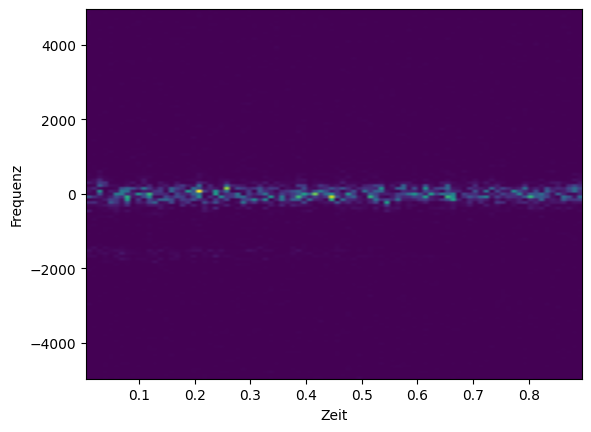

In [6]:

plt.imshow(
    summiert[1],
    aspect='auto',
    origin='lower',
      extent=[times.min(), times.max(), frequency.min(), frequency.max()]
)

plt.xlabel("Zeit")
plt.ylabel("Frequenz")
plt.show()


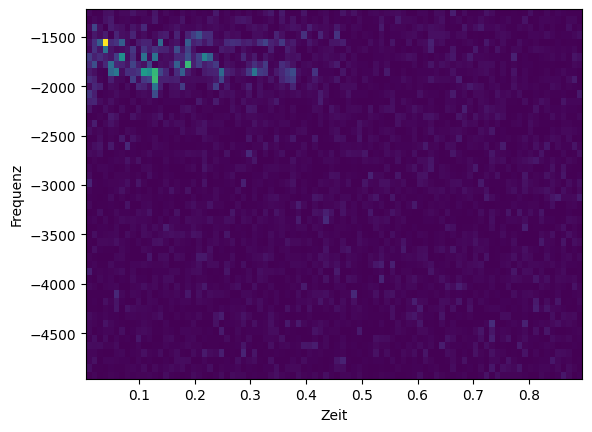

In [7]:
eins = summiert[47]
freq = frequency[:50]
plt.imshow(
    eins[:50,:],
    aspect='auto',
    origin='lower',
      extent=[times.min(), times.max(), freq.min(), freq.max()]
)

plt.xlabel("Zeit")
plt.ylabel("Frequenz")
plt.show()

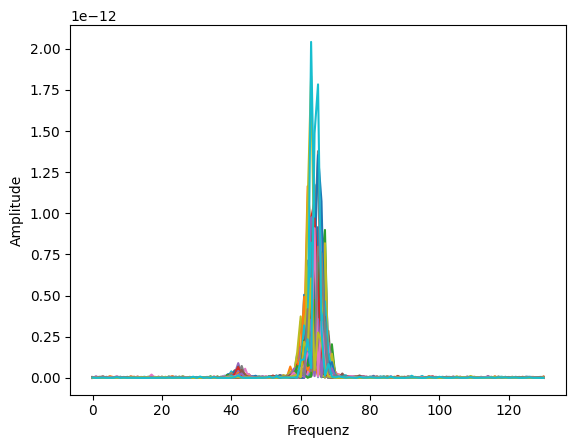

In [8]:
plt.plot(summiert[50])
plt.xlabel("Frequenz")
plt.ylabel("Amplitude")
plt.show()


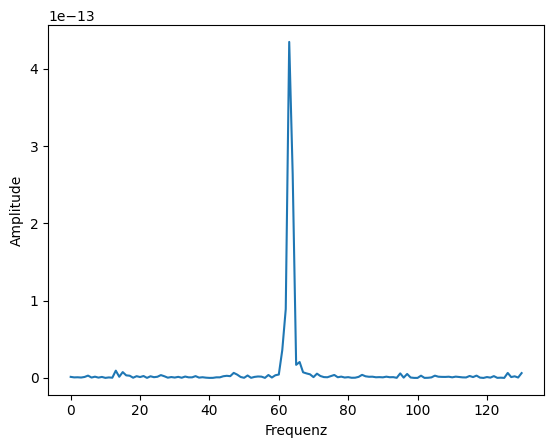

In [121]:
plt.plot(summiert[47][:,53])
plt.xlabel("Frequenz")
plt.ylabel("Amplitude")
plt.show()


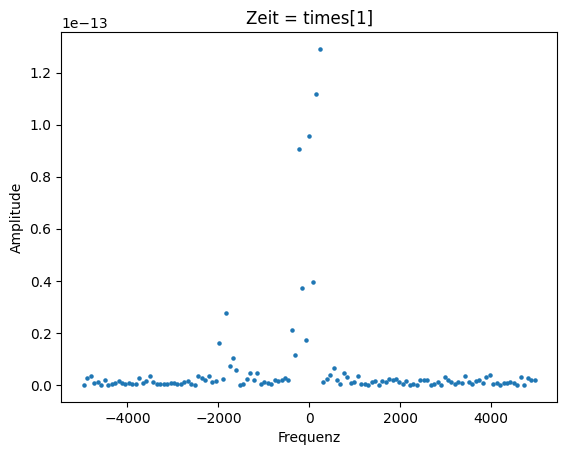

In [10]:
t=17
y = summiert[47][:, t]  
x = frequency            

plt.scatter(x, y, s=5)
plt.xlabel("Frequenz")
plt.ylabel("Amplitude")
plt.title("Zeit = times[1]")
plt.show()

# with Backround

In [11]:


def rem_backround(frequenzen, amplitudes, peak1_range, peak2_range):
    
    
    
    peak1 = (frequenzen > peak1_range[0]) & (frequenzen < peak1_range[1])
    peak2 = (frequenzen > peak2_range[0]) & (frequenzen < peak2_range[1])
    both_peaks = peak1 | peak2
    
    
    bg = ~both_peaks
    
    
    baseline_value = np.mean(amplitudes[bg])
    baseline = np.full_like(amplitudes, baseline_value)
    
    
    new_amplitueds = amplitudes - baseline
    
    return new_amplitueds, baseline

new_signal , new_bs = rem_backround(frequency, summiert[47][:, 5], (-2000,-1500), (-500,700) )





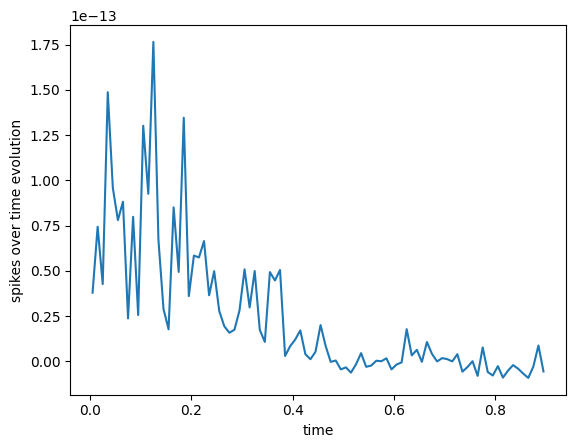

In [12]:
#sum of the Peak of the exited state without backround
def population(file_number):
    population = np.zeros(len(times))
    for i in range(0 , len(times)):
        new_signal, removed_bs = rem_backround(frequency, summiert[file_number][:, i], (-2000,-1500), (-500,700) )
        population[i] = np.sum(new_signal[40:50])
    return population
#sum of the Peak of the ground State without backround

def population_ground(file_number):
    population_ground = np.zeros(len(times))
    for i in range(0 , len(times)):
        new_signal, removed_bs = rem_backround(frequency, summiert[file_number][:, i], (-2000,-1500), (-500,700) )
        population_ground[i] = np.sum(new_signal[55:70]/10)
    return population_ground



time_evo_state = population(47)
time_ground_state = population_ground(40)

#forplot = time_evo_state + 5e-14 * ( np.exp(times))
#plan is to normalize the peak of the exited state with the peak of the ground state (not working because fluctuations multiply)
normalized_evo_state = time_evo_state / time_ground_state
    
plt.plot(times, time_evo_state)
#plt.plot(times, time_ground_state)
#plt.plot(times, forplot)
#plt.plot(times, normalized_evo_state)
plt.xlabel("time")
plt.ylabel("spikes over time evolution")
plt.show()







A = 5.109583776126063e-12
T_1/2 = 0.18588359607768784


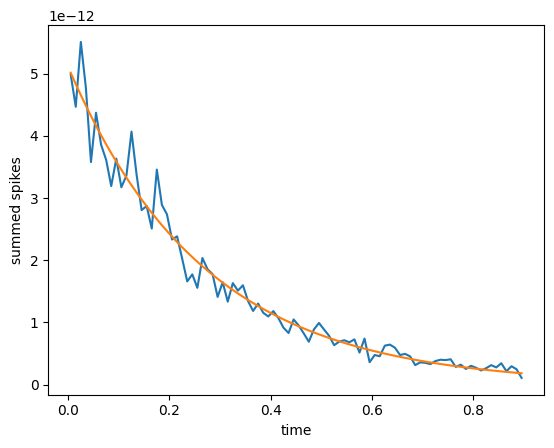

In [13]:

def sumation(anzahl):
    all_50_populations = np.zeros(len(times))
    for i in range(0 , anzahl):
        all_50_populations +=  population(i)
    return all_50_populations

summe = sumation(50)

from scipy.optimize import curve_fit

def zerfall(t, A, T_half):
    return A * np.exp(-np.log(2) * t / T_half)

# exponential decay Fit
p0 = [summe[0], (times[-1] - times[0]) / 2]   
popt, pcov = curve_fit(zerfall, times, summe, p0=p0)

A_fit, T_half_fit = popt
print("A =", A_fit)
print("T_1/2 =", T_half_fit)


t_fit = np.linspace(times.min(), times.max(), 500)
y_fit = zerfall(t_fit, *popt)


plt.plot(times, summe)
plt.plot(t_fit, y_fit)
plt.xlabel("time")
plt.ylabel("summed spikes")
plt.show()  




# gaußian fits (not working and not helpfull i think)

In [14]:

summiert[10][0:40,20] #zehnte messung bei 20 zeit und von frequenzen 1-40

def gauß_curve(frequency, A, mu, sigma, C):
    return A * np.exp(-(frequency - mu)**2 / (2 * sigma**2)) + C



def fit_gauß(y, frequency):

    
    A0 = np.max(y) - np.min(y)
    mu0 = frequency[np.argmax(y)]
    sigma0 = (frequency[-1] - frequency[0]) / 10
    C0 = np.min(y)
    
    p0 = [A0, mu0, sigma0, C0]
    
    

    popt, pcov = curve_fit(
        gauß_curve,
        frequency,
        y,
        p0=p0
    )
    
    A, mu, sigma, C = popt
    
    area = A * abs(sigma) * np.sqrt(2 * np.pi)
    
    return popt, area

ka , fläche =fit_gauß(summiert[10, :50, 1],frequency[0:50])
print(fläche)

def gaus_area_time_evo():
    popt = 0
    fittet = np.zeros((len(names), len(times)))
    for i in range(0 , len(names)):
        for j in range(0, len(times)):
            popt , fittet[i , j]= fit_gauß(summiert[i, :50 , j],frequency[:50])
    return fittet

fittet2 = gaus_area_time_evo()
print(fittet2)


#plt.plot(fittet2)
#plt.show()


5.309738487169781e-12


RuntimeError: Optimal parameters not found: Number of calls to function has reached maxfev = 1000.

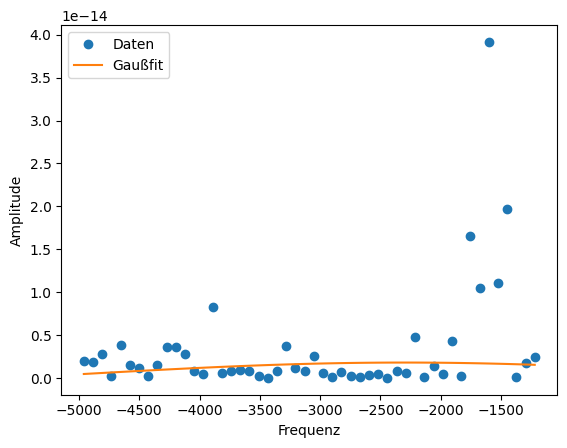

In [ ]:
y= summiert[10, :50, 0]
x = frequency[:50]
ka , fläche =fit_gauß(summiert[10, :50, 50],frequency[0:50])


plt.plot(x, y, "o", label="Daten")
plt.plot(x, gauß_curve(x, *ka), "-", label="Gaußfit")
plt.xlabel("Frequenz")
plt.ylabel("Amplitude")
plt.legend()
plt.show()

## not only summing up the extited peak area but everything. 


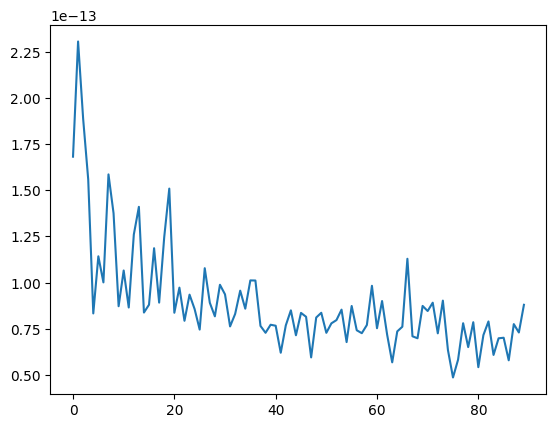

In [ ]:


def population2(file_number):
    population = np.zeros(len(times))
    for i in range(0 , len(times)):
        population[i] = np.sum(summiert[file_number, :50 , i])
    return population

all_summed_till_50 = population2(18)

plt.plot(all_summed_till_50)

# comparing with ground state to identify, when there are 0 exited ions left

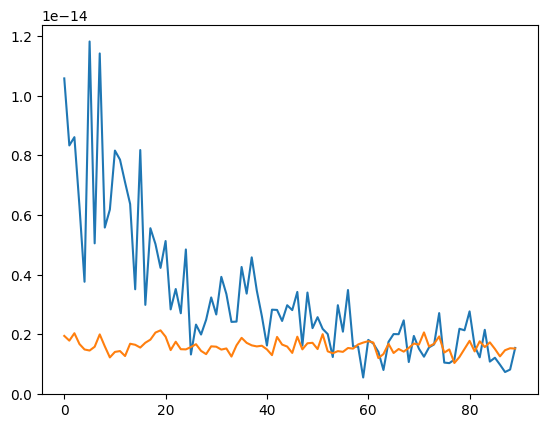

In [126]:
def population_normalized(file_number):
    population = np.zeros(len(times))
    for i in range(0 , len(times)):
        population[i] = np.sum(summiert[file_number, 38:49 , i]) / len((summiert[file_number, 38:49 , i]))
    return population




def backround_summed_normalized (frequenzen, amplitudes, peak1_range, peak2_range):
    
    peak1 = ( frequenzen > peak1_range[0]) & (frequenzen < peak1_range[1])
    peak2 = (frequenzen > peak2_range[0]) & (frequenzen < peak2_range[1])
    
    both_peaks = peak1 | peak2
    
    bg = ~both_peaks

    population_backround = np.zeros(len(times))
    for i in range(0, len(times)):
        backround_data = amplitudes[bg,i]
        population_backround[i] = np.sum(backround_data) / len(backround_data)

    
    return  population_backround

nr = 48
backround_data = backround_summed_normalized(frequency, summiert[nr][:, :], (-2100,-1400), (-600,600) )

time_evo_state = population_normalized(nr) 

plt.plot(time_evo_state)
plt.plot(backround_data)


no matching t found for messung 4


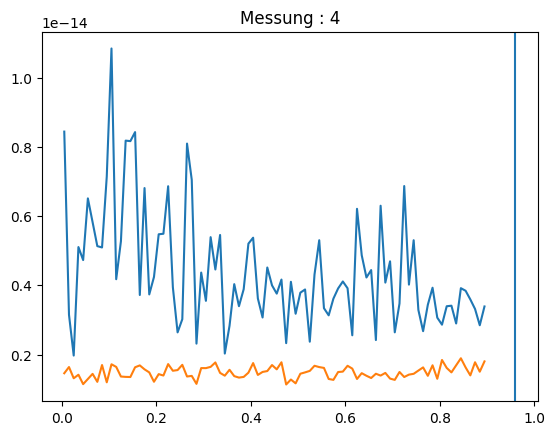

In [19]:
#####ONE STEP


def find_0_exited_state_t(backround, x , y, threshhold):
    for i in range(0 , len(y)):
        if abs(np.mean(y[i:]) - np.mean(backround)) < threshhold :
            t_all_ground = x[i]
            return t_all_ground
    print(f"no matching t found for messung {file_nr}")
    t_all_ground = 0.96
    return t_all_ground

    


file_nr = 4
t_ground = find_0_exited_state_t(backround_summed_normalized(frequency, summiert[file_nr][:, :], (-2100,-1400), (-600,600) ),
                                 times,
                                 population_normalized(file_nr),
                                 0.1 * 2e-15)

                                
### plot
plt.title(f"Messung : {file_nr}")
plt.plot(times, population_normalized(file_nr))
plt.plot(times, backround_summed_normalized(frequency, summiert[file_nr][:, :], (-2100,-1400),(-600,600) ))
plt.axvline(t_ground)


no matching t found for messung 3
no matching t found for messung 4
no matching t found for messung 6
no matching t found for messung 9
no matching t found for messung 19
no matching t found for messung 21
no matching t found for messung 22
no matching t found for messung 23
no matching t found for messung 24
no matching t found for messung 30
no matching t found for messung 31
no matching t found for messung 33
no matching t found for messung 35
no matching t found for messung 36
no matching t found for messung 39
no matching t found for messung 49
no matching t found for messung 50


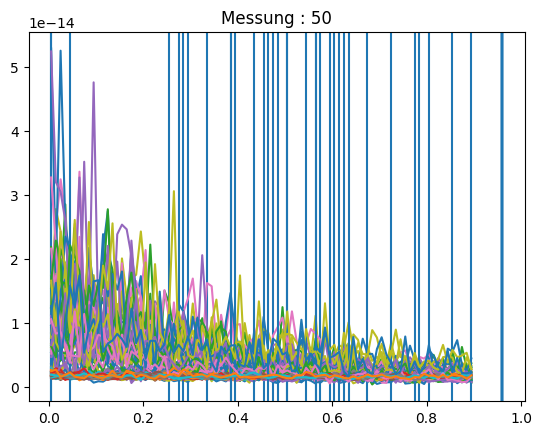

In [22]:

                            
for i in range(0 , len(names)):
    file_nr = i
    t_ground = find_0_exited_state_t(backround_summed_normalized(frequency, summiert[file_nr][:, :], (-2100,-1400), (-600,600) ),
                                 times,
                                 population_normalized(i),
                                 0.1 * 2e-15)
    #plt.figure()
    plt.title(f"Messung : {i}")
    plt.plot(times, population_normalized(i))
    plt.plot(times, backround_summed_normalized(frequency, summiert[i][:, :], (-2100,-1400),(-600,600) ))
    plt.axvline(t_ground)
    #plt.show()


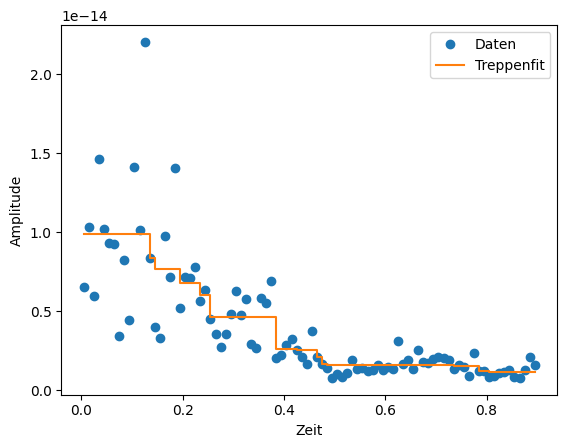

In [ ]:

#simple methode, but steps are to small which cannot
#!pip install scikit-learn
from sklearn.isotonic import IsotonicRegression

def fit_step_function(t, y):

    iso = IsotonicRegression(increasing=False, out_of_bounds="clip")
    y_fit = iso.fit_transform(t, y)

    return t, y, y_fit

t, y, y_fit = fit_step_function(times, population_normalized(47))

plt.plot(t, y, "o", label="Daten")
plt.step(t, y_fit, where="post", label="Treppenfit")
plt.xlabel("Zeit")
plt.ylabel("Amplitude")
plt.legend()
plt.show()

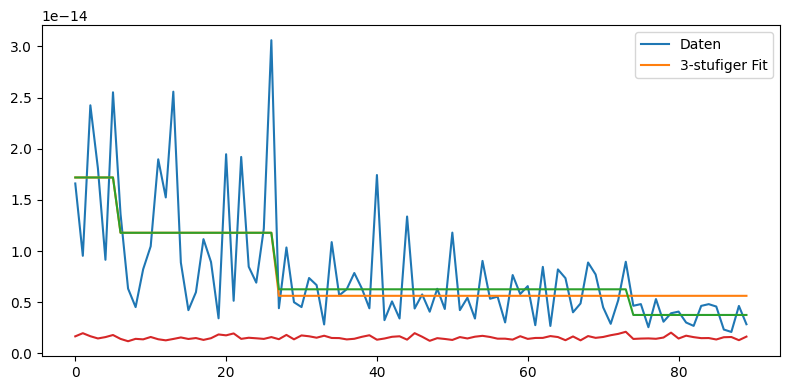

2.9842317490413657e-27
1.960449562438594e-27
1.8242841087244895e-27
1.7492605129313165e-27


In [181]:
y = population_normalized(49)
n = len(y)
x = np.arange(n)
def segment_sse(a, b, y):

    cs1 = np.cumsum(y)
    cs2 = np.cumsum(y**2)
    m = b - a
    s1 = cs1[b-1] - (cs1[a-1] if a > 0 else 0.0)
    s2 = cs2[b-1] - (cs2[a-1] if a > 0 else 0.0)
    mean = (s1 / m) 
    return s2 - 2*mean*s1 + m*mean**2

def steps_0(n, min_len=1):
    sse = segment_sse(0, n, y)
    return {"sse" : sse}



def steps_1(n,min_len=1):
    best_1 = None
    for k1 in range(min_len, n - min_len +1):

        l1 = y[:k1].mean()
        l2 = y[k1:].mean()
        if not (l1 >= l2 ):
                continue
        
        sse = segment_sse(0, k1, y) + segment_sse(k1, n ,y)
        if best_1 is None or sse < best_1["sse"]:
            best_1 = {"k1": k1, "sse": sse}
    return best_1



def steps_2(n, min_len=1):
    best_2 = None
    for k1 in range(min_len, n - 2*min_len + 1):
        for k2 in range(k1 + min_len, n - min_len + 1):

            l1 = y[:k1].mean()
            l2 = y[k1:k2].mean()
            l3 = y[k2:].mean()
             
            if not (l1 >= l2 >= l3):
                    continue

            sse = segment_sse(0, k1, y) + segment_sse(k1, k2, y) + segment_sse(k2, n, y)
            if best_2 is None or sse < best_2["sse"]:
                best_2 = {"k1": k1, "k2": k2, "sse": sse}
    return best_2



def steps_3(n, min_len=2):
    best_3 = None
    for k1 in range(min_len , n-3*min_len + 1):
        for k2 in range(k1 + min_len, n - 2*min_len + 1):
            for k3 in range(k2 + min_len, n - min_len + 1):
                l1 = y[:k1].mean()
                l2 = y[k1:k2].mean()
                l3 = y[k2:k3].mean()
                l4 = y[k3:].mean()

                if not (l1 >= l2 >= l3 >= l4):
                    continue
                sse = segment_sse(0, k1, y) + segment_sse(k1, k2, y) + segment_sse(k2, k3, y) + segment_sse(k3, n, y)
                if best_3 is None or sse < best_3["sse"]:
                    best_3 = {"k1": k1, "k2": k2, "k3" : k3, "sse": sse}
    return best_3 ####PUNISHMENT + 2e-28 or similar




best0 = steps_0(n)
best1 = steps_1(n)
best2 = steps_2(n)
best3 = steps_3(n)


k3_1, k3_2 , k3_3 = best3["k1"], best3["k2"], best3["k3"]
level3_1 = y[:k3_1].mean()
level3_2 = y[k3_1:k3_2].mean()
level3_3 = y[k3_2:k3_3].mean()
level3_4 = y[k3_3:].mean()
y_fit_3 = np.r_[np.full(k3_1, level3_1), np.full(k3_2-k3_1, level3_2), np.full(k3_3-k3_2, level3_3), np.full(n-k3_3, level3_4)]


k1, k2 = best2["k1"], best2["k2"]
level2_1 = y[:k1].mean()
level2_2 = y[k1:k2].mean()
level2_3 = y[k2:].mean()
y_fit_2 = np.r_[np.full(k1, level2_1), np.full(k2-k1, level2_2), np.full(n-k2, level2_3)]

#print("Sprungstellen bei Indizes:", times[k1], times[k2])
#print("Niveaus:", level2_1, level2_2, level2_3)

plt.figure(figsize=(8, 4))
plt.plot(x, y, label="Daten")
plt.plot(x, y_fit_2, "-", label="3-stufiger Fit")
plt.plot(x, y_fit_3)
plt.plot(x, backround_summed_normalized(frequency, summiert[47][:, :], (-2100,-1400),(-600,600) ))
#plt.axvline(k1, linestyle="--")
#plt.axvline(k2, linestyle="--")
plt.legend()
plt.tight_layout()
plt.show()


print(best0["sse"])
print(best1["sse"])
print(best2["sse"])
print(best3["sse"])


0
1
2
3
4
5
6
7
8
9
